# Low light image enhancement

The saved outputs show the completed Colab run and the follow-up experiments.
See the project README for setup and instructions to train or evaluate the saved model.

In [1]:
import os

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/SIGK/projekt_2")  # Adjust to your Drive folder.
    get_ipython().run_line_magic("pip", "install -r requirements.txt")

    import torch
    if torch.cuda.is_available():
        print(torch.cuda.get_device_name(0))

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 20.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [lpips]
Tesla T4


## 1. Config

In [2]:
from pathlib import Path
from urllib.parse import urlsplit
import csv
import hashlib
import json
import math
import os
import random
import time

import imageio.v2 as imageio
import lpips
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rawpy
import requests
from requests.adapters import HTTPAdapter
import torch
from skimage import exposure
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

ROOT = Path.cwd()
if not (ROOT / "RAISE_258.csv").is_file():
    ROOT = ROOT / "projekt_2"
if not (ROOT / "RAISE_258.csv").is_file():
    raise FileNotFoundError("Run from the repository root or the projekt_2 directory.")
import sys
sys.path.insert(0, str(ROOT))
import models
from models import (
    ExposurePerceptualLoss, LowLightEnhancer, NAFUNet, RestorationLoss,
    count_parameters, tiled_inference,
)

In [3]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("device:", DEVICE)

device: cuda


In [4]:
CFG = dict(
    # dane (zgodnie z poleceniem)
    device_model="Nikon D7000",
    keyword="Indoor",
    n_images=100,      # 100 pierwszych obrazów
    n_test=20,         # ewaluacja na 20 ostatnich
    n_val=10,          # walidacja: 10 obrazów przed zbiorem testowym
    ev_shift=-3.0,     # -3 EV = 8x mniej światła
    alpha=0.001,       # szum fotonowy (Poisson)
    sigma=0.005,       # szum elektroniczny (Gauss)
    gamma=2.2,
    # model
    width=32,
    enc_blocks=(1, 1, 2, 4),
    middle_blocks=4,
    dec_blocks=(1, 1, 1, 1),
    # trening
    patch=256,
    batch_size=8,
    crops_per_image=16,
    epochs=50,
    lr=1e-3,
    min_lr=1e-6,
    weight_decay=1e-4,
    loss="composite",  # "original" for Charbonnier + SSIM
    ssim_weight=0.1,
    exposure_weight=0.20,
    perceptual_weight=0.02,
    grad_clip=0.5,
    val_crop=512,
    seed=42,
    tile=512,
    tile_overlap=32,
)
TRAIN = True  # Set False to evaluate a saved checkpoint.

if CFG["loss"] not in ("original", "composite"):
    raise ValueError("Set loss to 'original' or 'composite'.")

CSV_PATH = ROOT / "RAISE_258.csv"
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
degradation = {k: CFG[k] for k in ("ev_shift", "alpha", "sigma", "gamma")}
cache_id = hashlib.sha256(json.dumps(degradation, sort_keys=True).encode()).hexdigest()[:12]
GT_DIR = DATA_DIR / "processed" / "gt"
DARK_DIR = DATA_DIR / "processed" / cache_id / "input"

RUNS_DIR = Path(os.environ.get("SIGK_RUNS_DIR", ROOT / "runs"))
RESULTS_DIR = RUNS_DIR / CFG["loss"]
CKPT_DIR = RESULTS_DIR / "checkpoints"
FIG_DIR = RESULTS_DIR / "figures"
for directory in (RAW_DIR, GT_DIR, DARK_DIR, CKPT_DIR, FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print("Run directory:", RESULTS_DIR)

Run directory: /content/drive/MyDrive/SIGK/projekt_2/runs/composite


## 2. Dataset

Funkcja z instrukcji

In [5]:
def select_rows(csv_path, device_model, keyword, limit):
    with open(csv_path, mode="r", encoding="utf-8") as f:
        rows = [r for r in csv.DictReader(f)
                if r["Device"].strip() == device_model and keyword in r["Keywords"]]
    return rows[:limit]


def download_raise_nef(rows, output_dir):
    with requests.Session() as session:
        session.mount("https://", HTTPAdapter(max_retries=3))
        for row in tqdm(rows, desc="download"):
            url = row["NEF"]
            parsed_url = urlsplit(url)
            if parsed_url.netloc == "193.205.194.113":
                url = parsed_url._replace(scheme="https", netloc="loki.disi.unitn.it").geturl()
            filename = row["File"]
            if not filename.upper().endswith(".NEF"):
                filename += ".NEF"
            filepath = output_dir / filename
            if filepath.is_file():
                continue
            tmp_path = filepath.with_suffix(".NEF.part")
            with session.get(url, stream=True, timeout=(15, 60)) as response:
                response.raise_for_status()
                with tmp_path.open("wb") as out_file:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        out_file.write(chunk)
            tmp_path.replace(filepath)


ROWS = select_rows(CSV_PATH, CFG["device_model"], CFG["keyword"], CFG["n_images"])
NAMES = [Path(row["File"]).stem for row in ROWS]
if len(NAMES) != CFG["n_images"] or len(set(NAMES)) != len(NAMES):
    raise ValueError("Expected 100 distinct images from the selected RAISE subset.")
download_raise_nef(ROWS, RAW_DIR)

download:   0%|          | 0/100 [00:00<?, ?it/s]

## 3. Preprocessing

In [6]:
def get_ground_truth(raw):
    # Properly exposed, full-colour sRGB image (Ground Truth); half_size for speed.
    return raw.postprocess(use_camera_wb=True, half_size=True)


def add_physical_noise(linear_img, rng, alpha=0.001, sigma=0.005):
    # alpha: Poisson (photon) noise, sigma: Gaussian (electronic read) noise
    noisy_img = rng.poisson(linear_img / alpha) * alpha
    noisy_img += rng.normal(0, sigma, linear_img.shape)
    return np.clip(noisy_img, 0.0, 1.0)


def get_linear_image(raw):
    # Linear image (no auto-brightness, no gamma), float32 in [0, 1].
    linear_16bit = raw.postprocess(
        use_camera_wb=True,
        gamma=(1, 1),
        no_auto_bright=True,
        output_bps=16,
        half_size=True,
    )
    return linear_16bit.astype(np.float32) / 65535.0


def reduce_exposure(linear_img, ev_shift):
    # -1 EV halves the light -> scale factor 2 ** ev_shift (-3 EV -> 1/8).
    return linear_img * (2.0 ** ev_shift)


def apply_gamma_correction(img, gamma=2.2):
    # Simplified sRGB gamma: img ** (1 / gamma).
    return np.power(np.clip(img, 0.0, 1.0), 1.0 / gamma)


def convert_to_8bit(img):
    # float [0, 1] -> uint8 [0, 255] with rounding.
    return np.clip(np.round(img * 255.0), 0, 255).astype(np.uint8)


def get_low_light(raw, rng, ev_shift=-3.0):
    linear_img = get_linear_image(raw)                                     # 1. linear data
    dark_linear = reduce_exposure(linear_img, ev_shift)                    # 2. -3 EV
    noisy_dark_linear = add_physical_noise(dark_linear, rng, CFG["alpha"], CFG["sigma"])  # 3. sensor noise
    dark_srgb = apply_gamma_correction(noisy_dark_linear, CFG["gamma"])    # 4. gamma
    return convert_to_8bit(dark_srgb)                                      # 5. 8 bit


def file_seed(name):
    return int(hashlib.md5(name.encode()).hexdigest()[:8], 16)


def process_single_file(file_path, output_gt_dir, output_dark_dir, ev_shift):
    base_name = file_path.stem
    gt_path = output_gt_dir / f"{base_name}_gt.png"
    dark_path = output_dark_dir / f"{base_name}_input.png"
    if gt_path.is_file() and dark_path.is_file():
        return
    with rawpy.imread(str(file_path)) as raw:
        img_gt = get_ground_truth(raw)
        rng = np.random.RandomState(file_seed(base_name))
        img_dark = get_low_light(raw, rng, ev_shift)
    if img_gt.shape != img_dark.shape:
        raise ValueError(f"Image sizes differ for {base_name}: {img_gt.shape} vs {img_dark.shape}")
    for path, image in ((gt_path, img_gt), (dark_path, img_dark)):
        tmp_path = path.with_suffix(".tmp.png")
        imageio.imwrite(tmp_path, image)
        tmp_path.replace(path)


for name in tqdm(NAMES, desc="process"):
    process_single_file(RAW_DIR / f"{name}.NEF", GT_DIR, DARK_DIR, CFG["ev_shift"])

process:   0%|          | 0/100 [00:00<?, ?it/s]

rozmiar: (1640, 2474, 3)
średnia jasność  input=0.111  amplified=0.287  GT=0.300


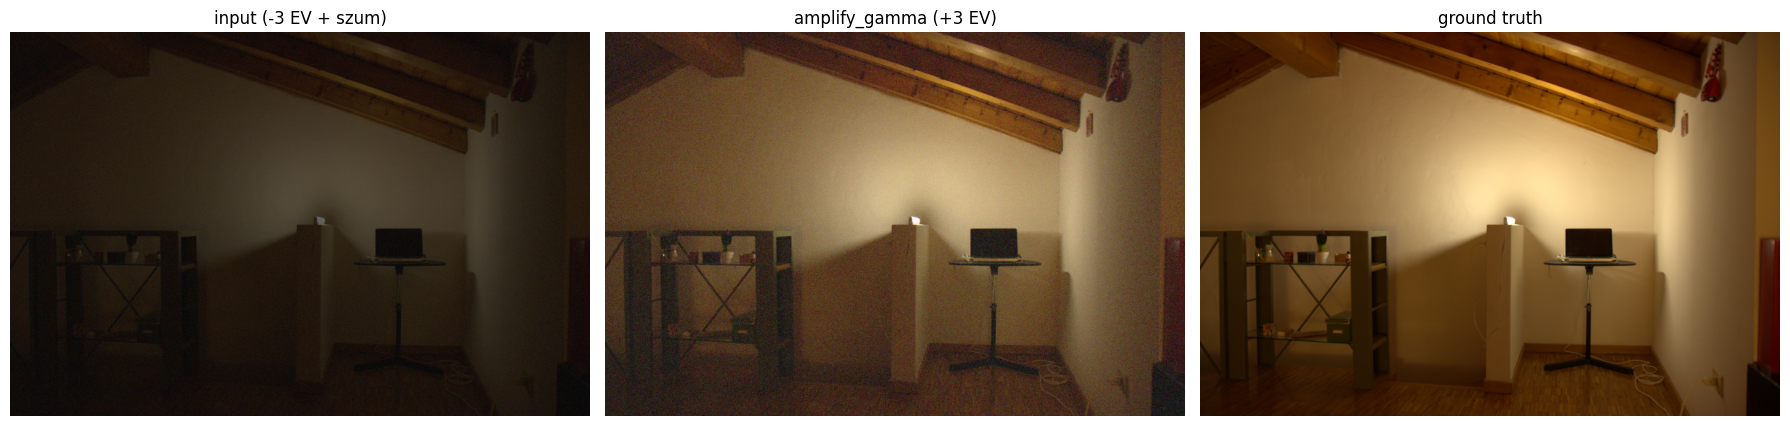

In [7]:
def load_pair(name):
    gt = imageio.imread(GT_DIR / f"{name}_gt.png")
    dark = imageio.imread(DARK_DIR / f"{name}_input.png")
    return dark, gt


def to_tensor(img_u8):
    return torch.from_numpy(img_u8).permute(2, 0, 1).float().div(255.0)


def to_numpy(t):
    return t.detach().clamp(0, 1).squeeze(0).permute(1, 2, 0).cpu().numpy()


dark, gt = load_pair(NAMES[0])
amp = to_numpy(models.amplify_gamma(to_tensor(dark)[None], 2.0 ** -CFG["ev_shift"], CFG["gamma"]))
print("rozmiar:", gt.shape)
print(f"średnia jasność  input={dark.mean()/255:.3f}  amplified={amp.mean():.3f}  GT={gt.mean()/255:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, img, t in zip(ax, [dark, amp, gt], ["input (-3 EV + szum)", "amplify_gamma (+3 EV)", "ground truth"]):
    a.imshow(img); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

## 4. Split

In [8]:
n_train = CFG["n_images"] - CFG["n_val"] - CFG["n_test"]
SPLIT = {
    "train": NAMES[:n_train],
    "val": NAMES[n_train:n_train + CFG["n_val"]],
    "test": NAMES[n_train + CFG["n_val"]:],
}
assert len(SPLIT["test"]) == CFG["n_test"] and SPLIT["test"] == NAMES[-CFG["n_test"]:]
assert not (set(SPLIT["train"]) & set(SPLIT["val"]) or set(SPLIT["train"]) & set(SPLIT["test"]))
(RESULTS_DIR / "split.json").write_text(json.dumps(SPLIT, indent=2))
print({k: len(v) for k, v in SPLIT.items()})

{'train': 70, 'val': 10, 'test': 20}


## 5. Training

In [9]:
class PairDataset(Dataset):
    def __init__(self, names, patch=None, crops_per_image=1, train=False, center_crop=None):
        self.pairs = [load_pair(n) for n in tqdm(names, desc="load", leave=False)]
        self.patch, self.train, self.center_crop = patch, train, center_crop
        self.length = len(self.pairs) * crops_per_image

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        dark, gt = self.pairs[idx % len(self.pairs)]
        h, w, _ = gt.shape
        if self.train:
            p = self.patch
            y, x = np.random.randint(0, h - p + 1), np.random.randint(0, w - p + 1)
            dark, gt = dark[y:y + p, x:x + p], gt[y:y + p, x:x + p]
            k = np.random.randint(4)
            dark, gt = np.rot90(dark, k), np.rot90(gt, k)
            if np.random.rand() < 0.5:
                dark, gt = dark[:, ::-1], gt[:, ::-1]
        elif self.center_crop:
            c = self.center_crop
            y, x = (h - c) // 2, (w - c) // 2
            dark, gt = dark[y:y + c, x:x + c], gt[y:y + c, x:x + c]
        return to_tensor(np.ascontiguousarray(dark)), to_tensor(np.ascontiguousarray(gt))


if TRAIN:
    train_ds = PairDataset(SPLIT["train"], CFG["patch"], CFG["crops_per_image"], train=True)
    val_ds = PairDataset(SPLIT["val"], center_crop=CFG["val_crop"])
    train_generator = torch.Generator()
    train_loader = DataLoader(
        train_ds, batch_size=CFG["batch_size"], shuffle=True, generator=train_generator,
        num_workers=0, drop_last=True,
    )
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

load:   0%|          | 0/70 [00:00<?, ?it/s]

load:   0%|          | 0/10 [00:00<?, ?it/s]

In [10]:
def build_model(cfg=None):
    cfg = CFG if cfg is None else cfg
    net = NAFUNet(width=cfg["width"], enc_blocks=cfg["enc_blocks"],
                  middle_blocks=cfg["middle_blocks"], dec_blocks=cfg["dec_blocks"])
    return LowLightEnhancer(net, gain=2.0 ** -cfg["ev_shift"], gamma=cfg["gamma"]).to(DEVICE)


@torch.no_grad()
def validate(model):
    model.eval()
    scores = []
    for dark, gt in val_loader:
        pred = model(dark.to(DEVICE)).clamp(0, 1)
        mse = torch.mean((pred - gt.to(DEVICE)) ** 2).item()
        scores.append(10 * math.log10(1.0 / max(mse, 1e-10)))
    return float(np.mean(scores))

In [11]:
BEST_CKPT = CKPT_DIR / "best.pt"
LAST_CKPT = CKPT_DIR / "last.pt"
HISTORY_PATH = RESULTS_DIR / "history.json"

if TRAIN:
    # Targets and VGG stay outside the optimizer. Seed after building the loss
    # so both experiments use the same model initialization.
    if CFG["loss"] == "composite":
        criterion = ExposurePerceptualLoss(
            ssim_weight=CFG["ssim_weight"],
            exposure_weight=CFG["exposure_weight"],
            perceptual_weight=CFG["perceptual_weight"],
        ).to(DEVICE)
    else:
        criterion = RestorationLoss(ssim_weight=CFG["ssim_weight"]).to(DEVICE)

    random.seed(CFG["seed"])
    torch.manual_seed(CFG["seed"])
    model = build_model()
    print(f"{models.MODEL_ARCHITECTURE}: {count_parameters(model) / 1e6:.2f} M params")
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"], betas=(0.9, 0.9),
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=CFG["epochs"] * len(train_loader), eta_min=CFG["min_lr"],
    )


    def save_checkpoint(state, path):
        tmp_path = path.with_suffix(".pt.tmp")
        torch.save(state, tmp_path)
        tmp_path.replace(path)


    def save_history(history):
        tmp_path = HISTORY_PATH.with_suffix(".json.tmp")
        tmp_path.write_text(json.dumps(history, indent=2), encoding="utf-8")
        tmp_path.replace(HISTORY_PATH)


    history = {"epoch": [], "train_loss": [], "val_psnr": [], "lr": []}
    start_epoch, best_psnr = 0, -math.inf
    if LAST_CKPT.exists():
        state = torch.load(LAST_CKPT, map_location="cpu", weights_only=True)
        if state.get("cfg") != CFG or state.get("split") != SPLIT:
            raise ValueError("Checkpoint settings differ. Restore the original settings or use a new SIGK_RUNS_DIR.")
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        start_epoch = state["epoch"] + 1
        best_psnr, history = state["best_psnr"], state["history"]
        del state
        save_history(history)
        print(f"Resuming after {start_epoch} completed epochs, best validation PSNR {best_psnr:.2f} dB")

    for epoch in range(start_epoch, CFG["epochs"]):
        np.random.seed(CFG["seed"] + epoch)
        train_generator.manual_seed(CFG["seed"] + epoch)
        model.train()
        t0, losses = time.time(), []
        for dark, gt in tqdm(train_loader, desc=f"epoch {epoch + 1}/{CFG['epochs']}", leave=False):
            dark, gt = dark.to(DEVICE), gt.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(dark), gt)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
            optimizer.step()
            scheduler.step()
            losses.append(loss.item())

        val_psnr = validate(model)
        train_loss = float(np.mean(losses))
        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["val_psnr"].append(val_psnr)
        history["lr"].append(scheduler.get_last_lr()[0])
        model_state = {"model": model.state_dict(), "epoch": epoch, "val_psnr": val_psnr, "cfg": CFG}
        if val_psnr > best_psnr:
            best_psnr = val_psnr
            save_checkpoint(model_state, BEST_CKPT)
        save_checkpoint(
            {**model_state, "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
             "best_psnr": best_psnr, "history": history, "split": SPLIT}, LAST_CKPT,
        )
        save_history(history)
        print(f"epoch {epoch + 1:3d}  loss {train_loss:.4f}  val PSNR {val_psnr:.2f} dB  "
              f"(best {best_psnr:.2f})  {time.time() - t0:.0f}s")

else:
    if not (BEST_CKPT.is_file() and HISTORY_PATH.is_file()):
        saved_run = ROOT / "results" / CFG["loss"]
        BEST_CKPT = saved_run / "best.pt"
        HISTORY_PATH = saved_run / "history.json"
    if not (BEST_CKPT.is_file() and HISTORY_PATH.is_file()):
        raise FileNotFoundError("No saved model and history for this loss. Set TRAIN=True to train it.")
    print("Using saved model:", BEST_CKPT)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 70.4MB/s]


naf_unet_v1: 11.57 M params


epoch 1/50:   0%|          | 0/140 [00:00<?, ?it/s]

epoch   1  loss 0.1504  val PSNR 16.52 dB  (best 16.52)  99s


epoch 2/50:   0%|          | 0/140 [00:00<?, ?it/s]

... (93 outputs left out)

epoch 49/50:   0%|          | 0/140 [00:00<?, ?it/s]

epoch  49  loss 0.0618  val PSNR 16.12 dB  (best 18.15)  103s


epoch 50/50:   0%|          | 0/140 [00:00<?, ?it/s]

epoch  50  loss 0.0642  val PSNR 16.13 dB  (best 18.15)  103s


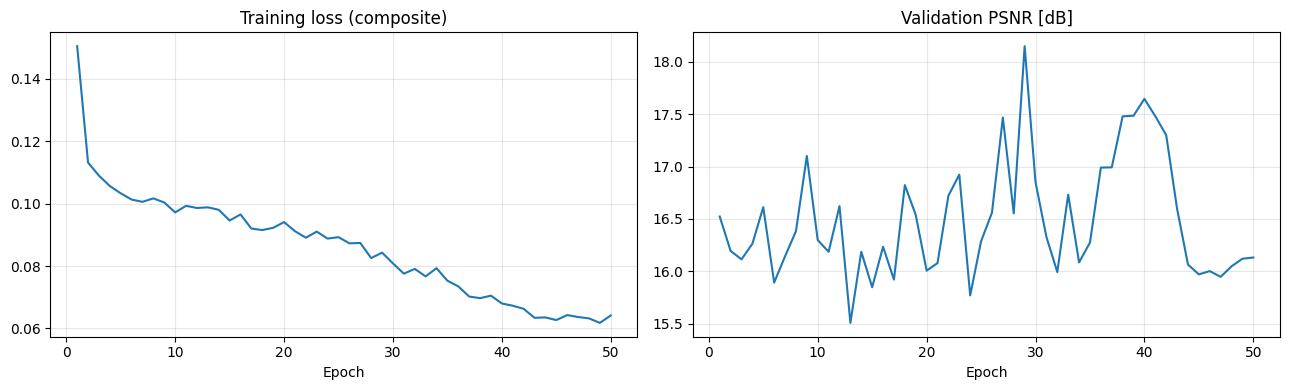

best model: epoch 29, val PSNR 18.15 dB


In [12]:
history = json.loads(HISTORY_PATH.read_text(encoding="utf-8"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history["epoch"], history["train_loss"])
ax[0].set_title(f"Training loss ({CFG['loss']})")
ax[1].plot(history["epoch"], history["val_psnr"])
other_loss = "original" if CFG["loss"] == "composite" else "composite"
other_history = RUNS_DIR / other_loss / "history.json"
if other_history.is_file():
    comparison = json.loads(other_history.read_text(encoding="utf-8"))
    ax[1].lines[0].set_label(CFG["loss"])
    ax[1].plot(comparison["epoch"], comparison["val_psnr"], label=other_loss)
    ax[1].legend()
ax[1].set_title("Validation PSNR [dB]")
for a in ax:
    a.set_xlabel("Epoch")
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "training_curves.png", dpi=150)
plt.show()

state = torch.load(BEST_CKPT, map_location="cpu", weights_only=True)
model = build_model(state["cfg"])
model.load_state_dict(state["model"])
model.eval()
print(f"best model: epoch {state['epoch'] + 1}, val PSNR {state['val_psnr']:.2f} dB")

## 6. Baseline i ewaluacja

**Baseline — wyrównanie histogramu.**

In [13]:
def rgb_to_ycbcr(img):
    r, g, b = img[..., 0], img[..., 1], img[..., 2]
    y = 0.299 * r + 0.587 * g + 0.114 * b
    cb = 0.5 + (b - y) * 0.564
    cr = 0.5 + (r - y) * 0.713
    return y, cb, cr


def ycbcr_to_rgb(y, cb, cr):
    r = y + 1.403 * (cr - 0.5)
    b = y + 1.773 * (cb - 0.5)
    g = (y - 0.299 * r - 0.114 * b) / 0.587
    return np.clip(np.stack([r, g, b], axis=-1), 0, 1)


def histogram_equalization(dark_u8):
    y, cb, cr = rgb_to_ycbcr(dark_u8.astype(np.float32) / 255.0)
    y_eq = exposure.equalize_hist(y, nbins=256)
    return ycbcr_to_rgb(y_eq, cb, cr).astype(np.float32)


@torch.no_grad()
def enhance(model, dark_u8):
    x = to_tensor(dark_u8)[None].to(DEVICE)
    return to_numpy(tiled_inference(model, x, CFG["tile"], CFG["tile_overlap"]))


lpips_fn = lpips.LPIPS(net="alex", verbose=False).to(DEVICE).eval()


@torch.no_grad()
def compute_metrics(pred, gt):
    psnr = peak_signal_noise_ratio(gt, pred, data_range=1.0)
    ssim = structural_similarity(gt, pred, channel_axis=-1, data_range=1.0)
    t = lambda a: torch.from_numpy(a).permute(2, 0, 1)[None].float().to(DEVICE) * 2 - 1
    lp = lpips_fn(t(pred), t(gt)).item()
    return psnr, ssim, lp

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 127MB/s] 


In [14]:
PRED_DIR = RESULTS_DIR / "test_predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

rows = []
for name in tqdm(SPLIT["test"], desc="test"):
    dark, gt_u8 = load_pair(name)
    gt = gt_u8.astype(np.float32) / 255.0
    outputs = {
        "input": dark.astype(np.float32) / 255.0,
        "baseline": histogram_equalization(dark),
        "network": enhance(model, dark),
    }
    imageio.imwrite(PRED_DIR / f"{name}_network.png", convert_to_8bit(outputs["network"]))
    imageio.imwrite(PRED_DIR / f"{name}_baseline.png", convert_to_8bit(outputs["baseline"]))
    for method, pred in outputs.items():
        psnr, ssim, lp = compute_metrics(pred, gt)
        rows.append({"image": name, "method": method, "PSNR": psnr, "SSIM": ssim, "LPIPS": lp})

per_image = pd.DataFrame(rows)
per_image.to_csv(RESULTS_DIR / "metrics_per_image.csv", index=False)
summary = per_image.groupby("method")[["PSNR", "SSIM", "LPIPS"]].mean()
summary.loc[["baseline", "network"]].to_csv(RESULTS_DIR / "metrics.csv")

test:   0%|          | 0/20 [00:00<?, ?it/s]

In [15]:
table = summary.loc[["baseline", "network"]].rename_axis("Metoda")
display(table.style.format({"PSNR": "{:.2f}", "SSIM": "{:.4f}", "LPIPS": "{:.4f}"}))

print("Ciemne wejście (bez obróbki):")
print(summary.loc[["input"]].round(4).to_string())
print("\nOdchylenie standardowe po obrazach:")
print(per_image.groupby("method")[["PSNR", "SSIM", "LPIPS"]].std().round(4).to_string())

,PSNR,SSIM,LPIPS
Metoda,,,
baseline,11.28,0.1528,1.0742
network,21.88,0.7015,0.3036


Ciemne wejście (bez obróbki):
           PSNR    SSIM   LPIPS
method                         
input   11.7858  0.2567  0.7393

Odchylenie standardowe po obrazach:
            PSNR    SSIM   LPIPS
method                          
baseline  3.5316  0.1209  0.2385
input     3.8887  0.0606  0.2110
network   4.5014  0.1428  0.1177


## 7. Follow-up experiments

Saved output from the Colab comparison. Set RUN_EXPERIMENTS = True to rerun it after the composite training run creates both checkpoints.

In [2]:
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    import subprocess

    experiment_device = "cuda" if DEVICE.type == "cuda" else "cpu"
    subprocess.run(
        [sys.executable, "-u", str(ROOT / "experiments.py"), "--device", experiment_device],
        check=True,
    )

Device: cuda
Reference: 50/50 epochs completed in /content/drive/MyDrive/SIGK/projekt_2/runs/composite
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth
100% 233M/233M [00:01<00:00, 181MB/s]
Full-image validation: composite_best: 100% 10/10 [00:48<00:00,  4.84s/it]
Full-image validation: c